# Grad-CAM for a whole class — GT boxes + predicted boxes + IoU (YOLO family notebook)

Works for **YOLOv8n** (default), **YOLO12n** and **YOLO26n**: change `MODEL_TAG` and the checkpoint pattern, run, and each run writes one *bundle* (`<MODEL_TAG>.pkl`) + a 2-row figure. The second notebook (`Combine_GradCAM_figure_all_models.ipynb`) stacks the bundles of all models into one figure.

**What is drawn**
* **Whole class**: the class (e.g. *car*) is chosen, then **every GT instance** of that class (green) and **every predicted box** of that class from each model (red) are drawn.
* **Row 1** (full image): `RGB image | YGB image | LGB image | RGB Grad-CAM | YGB Grad-CAM | LGB Grad-CAM`.
* **Row 2**: the same six panels **zoomed on the highest-scoring object** of that class.
* Nothing is converted or turned gray: the stored `SIMD_RGB / SIMD_YGB / SIMD_LGB` files are read, and each model gets its own file.

**Choice of class / image / object (automatic, by score)**: the RGB model's **highest-scoring correct prediction** (class matches a GT box, IoU ≥ `MATCH_IOU`) gives the *class id*, the *image* (if `IMAGE_STEM=None`) and the *focus object* (the one that is zoomed). Manual choice (class id 0–14, image, object) is available as a commented block in the settings cell.

| Concept | DIP theory | Where |
|---|---|---|
| Image = matrix of channels, resize | digital image, bilinear interpolation | `read_image_rgb`, `prepare_input` |
| IoU | region overlap (intersection / union) | `iou_xyxy` |
| Grad-CAM map → image size, heat-map colouring | up-sampling, min–max normalisation, pseudo-colour, alpha blending | `generate_gradcam`, `overlay_cam` |
| Clusters of activation | thresholding, connected components, centroid | `cam_metrics` |
| GT brightness / colour variance | mean / variance | `cam_metrics` |

## 1. Imports

In [12]:
# !pip install grad-cam ultralytics opencv-python matplotlib pandas pyyaml --user
from pathlib import Path
import json, math, pickle
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Patch
import torch
from ultralytics import YOLO
from pytorch_grad_cam import GradCAM
try:
    from ultralytics.utils.nms import non_max_suppression
except ImportError:
    from ultralytics.utils.ops import non_max_suppression

DEVICE = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__, "| device:", DEVICE)

PyTorch: 2.7.1+cu118 | device: cuda:0


## 2. Settings

* `MODEL_TAG`: label used in file names and the figure (`"YOLOv8n"`, `"YOLO12n"`, `"YOLO26n"`).
* `CKPT_PATTERN`: where the three `best.pt` files are; `{dataset}`, `{c}` (RGB/YGB/LGB) and `{tag}` are filled in.
* `USE_SAVED_SELECTION`: **keep `True` for YOLO12n / YOLO26n** after YOLOv8n has been run, so all models explain the *same image and class*. Set `False` (or delete `selection.json`) to select again.
* `TARGET_SCALE`: Grad-CAM layer = the feature map that feeds the detection head: `0` = P3 (stride 8, 80×80, best for small objects), `1` = P4, `2` = P5. It is read from the head, so it is the correct layer for every YOLO version.
* `CAM_MODE`: `"class_gt"` = the target uses all predictions centred on **any GT box of the class** (whole class); `"object"` = only the focus object; `"global"` = top-k scores of the class over the whole image.

In [13]:
# ================= USER SETTINGS =================
MODEL_TAG    = "YOLO26n"                      # "YOLOv8n" | "YOLO12n" | "YOLO26n"
DATASET_NAME = "SSL"                         # "SIMD" | "SSL"
PROJECT_ROOT = Path(r"C:\Users\DELL\Desktop\c")
SPLIT        = "test"
CKPT_PATTERN = str(PROJECT_ROOT / "runs" / "detect" / "runs" / "{dataset}_{c}_{tag}_weighted" / "weights" / "best.pt")

DATASET_CLASSES = {
    "SSL":  ['airplane', 'boat', 'car', 'ship'],
    "SIMD": ['car','truck','van','longvehicle','bus','airliner','propeller','trainer',
             'chartered','fighter','other','stairtruck','pushbacktruck','helicopter','boat'],
}
CLASS_NAMES = DATASET_CLASSES[DATASET_NAME]

# ---------- automatic selection (default): highest-scoring correct RGB prediction ----------
IMAGE_STEM      = None      # None -> scan the first MAX_SCAN test images and take the best one
MAX_SCAN        = 100
CLASS_ID        = None      # None -> class of the highest-scoring correct prediction
FOCUS_GT_INDEX  = None      # None -> the GT object matched by that highest-scoring prediction (the zoomed one)
USE_SAVED_SELECTION = False # True for YOLO12n / YOLO26n: reuse selection.json written by the first run

# ---------- MANUAL selection 
#class ids SIMD: 0 car, 1 truck, 2 van, 3 longvehicle, 4 bus, 5 airliner, 6 propeller, 7 trainer,
#                 8 chartered, 9 fighter, 10 other, 11 stairtruck, 12 pushbacktruck, 13 helicopter, 14 boat
#class ids SSL : 0 airplane, 1 boat, 2 car, 3 ship
#CLASS_ID       = 5          # choose the class (0..14)  -> the best image for that class is searched automatically
#IMAGE_STEM     = "0020"     # or force one image
#FOCUS_GT_INDEX = 3          # or force which GT object is zoomed (row number in the printed GT table)

COLORS      = ["RGB", "YGB", "LGB"]
IMAGE_SIZE  = 640
TARGET_SCALE = 0            # 0=P3 (80x80)  1=P4 (40x40)  2=P5 (20x20)
CAM_MODE    = "class_gt"    # "class_gt" | "object" | "global"
TOP_K       = 10            # top-k anchors per GT object summed into the Grad-CAM target
GT_PAD_PX   = 8

DET_CONF, DET_IOU = 0.25, 0.45
MATCH_IOU   = 0.5
CAM_THR, MIN_CLUSTER_PX = 0.5, 64
ZOOM_MIN_HALF = 64          # zoom window half-size (px, 640 frame); grows if the object is bigger

DATASET_DIRS = {c: PROJECT_ROOT / f"{DATASET_NAME}_{c}" for c in COLORS}
CHECKPOINTS  = {c: Path(CKPT_PATTERN.format(dataset=DATASET_NAME, c=c, tag=MODEL_TAG)) for c in COLORS}
OUTPUT_DIR   = PROJECT_ROOT / f"GradCAM_{DATASET_NAME}_class_figures"      # shared by all models
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
for c in COLORS:
    assert DATASET_DIRS[c].is_dir(), f"missing {DATASET_DIRS[c]}"
    assert CHECKPOINTS[c].is_file(), f"missing {CHECKPOINTS[c]}"
print(MODEL_TAG, "| outputs ->", OUTPUT_DIR)

YOLO26n | outputs -> C:\Users\DELL\Desktop\c\GradCAM_SSL_class_figures


## 3. Helpers: reading the stored images, labels, models

**DIP:** an image is an `H×W×3` matrix; `cv2.imread` gives B,G,R order, so it is flipped to R,G,B (`img[..., ::-1]`).
`prepare_input` resizes to 640×640 (bilinear: each new pixel = weighted mean of its 4 nearest old pixels; row `[0,100]` → 3 samples `[0,50,100]`) and divides by 255 (network input in 0–1).
YOLO label `class cx cy w h` is normalised; because the image is squashed to a square, pixels = fraction × 640.

In [14]:
IMG_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}

def find_split_dir(root, split):
    for p in Path(root).iterdir():
        if p.is_dir() and p.name.lower() == split.lower(): return p
    raise FileNotFoundError(f"No '{split}' folder inside {root}")

SPLIT_DIRS = {c: find_split_dir(DATASET_DIRS[c], SPLIT) for c in COLORS}
IMAGE_MAPS = {c: {p.stem: p for p in (SPLIT_DIRS[c] / "images").iterdir() if p.suffix.lower() in IMG_EXTS} for c in COLORS}
COMMON_STEMS = sorted(set.intersection(*(set(IMAGE_MAPS[c]) for c in COLORS)))
print("images present in RGB, YGB and LGB:", len(COMMON_STEMS))

def read_image_rgb(path):
    bgr = cv2.imread(str(path), cv2.IMREAD_COLOR)
    if bgr is None: raise RuntimeError(f"Could not read {path}")
    return cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)

def parse_yolo_file(path):
    rows = []
    if Path(path).exists():
        for line in Path(path).read_text().splitlines():
            p = line.split()
            if len(p) >= 5: rows.append([float(v) for v in p[:5]])
    return np.array(rows, dtype=np.float32).reshape(-1, 5)

def yolo_to_xyxy(row, size=IMAGE_SIZE):
    _, cx, cy, w, h = row
    return np.array([(cx-w/2)*size, (cy-h/2)*size, (cx+w/2)*size, (cy+h/2)*size], dtype=np.float32)

def load_gt(stem):
    return parse_yolo_file(SPLIT_DIRS["RGB"] / "labels" / f"{stem}.txt")

def prepare_input(img_rgb_uint8):
    resized = cv2.resize(img_rgb_uint8, (IMAGE_SIZE, IMAGE_SIZE), interpolation=cv2.INTER_LINEAR)
    t = torch.from_numpy(resized.astype(np.float32) / 255.0).permute(2, 0, 1).unsqueeze(0).to(DEVICE).float()
    return resized, t

yolo_models, torch_models, TARGET_LAYERS = {}, {}, {}
for c in COLORS:
    yolo_models[c] = YOLO(str(CHECKPOINTS[c]))
    net = yolo_models[c].model.to(DEVICE).eval()
    head = net.model[-1]
    if getattr(head, "end2end", False):             # YOLO26 is NMS-free by default; use the standard (one-to-many) head
        try: head.end2end = False; print(f"{c}: end2end head switched to NMS-style output")
        except Exception as e: print("could not switch end2end:", e)
    torch_models[c] = net
    TARGET_LAYERS[c] = head.f[TARGET_SCALE]          # layer index that feeds the head at the chosen scale
print("Grad-CAM layer index per model:", TARGET_LAYERS, "->", torch_models["RGB"].model[TARGET_LAYERS["RGB"]].__class__.__name__)

images present in RGB, YGB and LGB: 127
Grad-CAM layer index per model: {'RGB': 16, 'YGB': 16, 'LGB': 16} -> C3k2


## 4. Boxes, IoU, detections

**IoU = overlap area / union area**, `union = areaA + areaB − overlap`. Tiny example: two 10×10 boxes shifted by 5 px → 50 / 150 = **0.333**.

`detect` = one forward pass + NMS (keep the best-scoring box, drop boxes overlapping it by more than `DET_IOU`).
`class_only` keeps just the chosen class, so **all instances of that class** are returned.
`match_class` greedily pairs predictions (highest confidence first) with GT boxes at IoU ≥ `MATCH_IOU` → TP count, per-GT best IoU.

In [15]:
def box_area(b): return max(0.0, float(b[2]-b[0])) * max(0.0, float(b[3]-b[1]))

def iou_xyxy(a, b):
    ix1, iy1, ix2, iy2 = max(a[0],b[0]), max(a[1],b[1]), min(a[2],b[2]), min(a[3],b[3])
    inter = max(0.0, ix2-ix1) * max(0.0, iy2-iy1)
    union = box_area(a) + box_area(b) - inter
    return inter/union if union > 0 else 0.0
print("IoU check:", round(iou_xyxy([0,0,10,10],[5,0,15,10]), 3), "(expect 0.333)")

@torch.no_grad()
def detect(color, stem):
    _, x = prepare_input(read_image_rgb(IMAGE_MAPS[color][stem]))
    out = torch_models[color](x)
    pred = out[0] if isinstance(out, (tuple, list)) else out
    if pred.shape[-1] == 6:                                   # NMS-free output: x1,y1,x2,y2,conf,cls
        r = pred[0].cpu().numpy(); return r[r[:, 4] >= DET_CONF]
    return non_max_suppression(pred, conf_thres=DET_CONF, iou_thres=DET_IOU, max_det=300)[0].cpu().numpy()

def class_only(dets, cls_id):
    return dets[dets[:, 5] == cls_id] if len(dets) else np.zeros((0, 6), np.float32)

def match_class(gt_boxes, preds, thr=MATCH_IOU):
    # returns: TP, per-GT best IoU (max over predictions), matched pred index per GT (greedy by confidence)
    best = [max([iou_xyxy(p[:4], g) for p in preds], default=0.0) for g in gt_boxes]
    used, tp, match = set(), 0, {}
    for pi in np.argsort(-preds[:, 4]) if len(preds) else []:
        cand = [(iou_xyxy(preds[pi][:4], g), gi) for gi, g in enumerate(gt_boxes) if gi not in used]
        if cand:
            v, gi = max(cand)
            if v >= thr: used.add(gi); tp += 1; match[gi] = int(pi)
    return tp, best, match

def best_correct_detection(stem, cls_filter=None):
    # highest-scoring RGB-model detection whose class matches a GT box with IoU >= MATCH_IOU
    gt = load_gt(stem); dets = detect("RGB", stem); best = None
    for d in dets:
        if cls_filter is not None and int(d[5]) != cls_filter: continue
        for gi, g in enumerate(gt):
            if int(g[0]) == int(d[5]) and iou_xyxy(d[:4], yolo_to_xyxy(g)) >= MATCH_IOU:
                if best is None or d[4] > best[0]: best = (float(d[4]), int(d[5]), gi)
    return best        # (conf, class_id, gt_index) or None

IoU check: 0.333 (expect 0.333)


## 5. Choose the image, the class and the focus object

Automatic rule: **highest-scoring correct prediction of the RGB model** → class id, image, focus object (zoomed). The class id then selects **all** GT boxes of that class in the image.
The selection is saved to `selection.json` so YOLO12n / YOLO26n / Faster R-CNN can explain the same image and class.

In [16]:
sel_file = OUTPUT_DIR / "selection.json"
if USE_SAVED_SELECTION and sel_file.exists():
    sel = json.loads(sel_file.read_text())
    IMAGE_STEM, CLASS_ID, FOCUS_GT_INDEX = sel["image_stem"], sel["class_id"], sel["focus_gt_index"]
    print("loaded saved selection:", sel)
else:
    if IMAGE_STEM is None:
        scores = []
        for s in COMMON_STEMS[:MAX_SCAN]:
            b = best_correct_detection(s, CLASS_ID)
            if b: scores.append((b[0], s))
        assert scores, "no correct RGB detection found (check CLASS_ID / MAX_SCAN)"
        IMAGE_STEM = max(scores)[1]
        print("auto-selected image:", IMAGE_STEM, "| top score", round(max(scores)[0], 3))
    labels = load_gt(IMAGE_STEM)
    b = best_correct_detection(IMAGE_STEM, CLASS_ID)
    if CLASS_ID is None:
        CLASS_ID = b[1] if b else int(labels[0, 0])
    if FOCUS_GT_INDEX is None:
        FOCUS_GT_INDEX = b[2] if (b and b[1] == CLASS_ID) else int(next(i for i, r in enumerate(labels) if int(r[0]) == CLASS_ID))
    sel_file.write_text(json.dumps(dict(image_stem=IMAGE_STEM, class_id=int(CLASS_ID), focus_gt_index=int(FOCUS_GT_INDEX))))
    print("saved selection ->", sel_file)

labels = load_gt(IMAGE_STEM)
CLS_GT_IDX = [i for i, r in enumerate(labels) if int(r[0]) == CLASS_ID]            # every GT instance of the class
assert FOCUS_GT_INDEX in CLS_GT_IDX, "FOCUS_GT_INDEX must be a GT object of the chosen class"
GT_BOXES   = [yolo_to_xyxy(labels[i]) for i in CLS_GT_IDX]
FOCUS_LOCAL = CLS_GT_IDX.index(FOCUS_GT_INDEX)
FOCUS_BOX  = GT_BOXES[FOCUS_LOCAL]
CLASS_NAME = CLASS_NAMES[CLASS_ID]
print(f"image {IMAGE_STEM} | class {CLASS_ID} ({CLASS_NAME}) | {len(GT_BOXES)} GT instances | focus GT#{FOCUS_GT_INDEX} box {np.round(FOCUS_BOX).astype(int).tolist()}")

IMG_FULL = {c: read_image_rgb(IMAGE_MAPS[c][IMAGE_STEM]) for c in COLORS}          # the stored RGB / YGB / LGB files
INPUT_U8 = {c: prepare_input(IMG_FULL[c])[0] for c in COLORS}                       # 640x640x3 uint8, shown in the figure
ORIG_640 = INPUT_U8["RGB"]

# zoom window around the focus object (same window for all models/rows)
fw, fh = FOCUS_BOX[2] - FOCUS_BOX[0], FOCUS_BOX[3] - FOCUS_BOX[1]
half = int(min(320, max(ZOOM_MIN_HALF, 1.0 * max(fw, fh))))
zcx, zcy = (FOCUS_BOX[0] + FOCUS_BOX[2]) / 2, (FOCUS_BOX[1] + FOCUS_BOX[3]) / 2
zx0 = int(np.clip(zcx - half, 0, IMAGE_SIZE - 2 * half)); zy0 = int(np.clip(zcy - half, 0, IMAGE_SIZE - 2 * half))
ZOOM = (zx0, zy0, zx0 + 2 * half, zy0 + 2 * half)
print("zoom window:", ZOOM)

auto-selected image: sample_01078 | top score 0.755
saved selection -> C:\Users\DELL\Desktop\c\GradCAM_SSL_class_figures\selection.json
image sample_01078 | class 0 (airplane) | 15 GT instances | focus GT#13 box [535, 229, 576, 320]
zoom window: (458, 183, 640, 365)


## 6. Grad-CAM

1. Forward pass; take the feature maps `Aᵏ` of the layer that feeds the head.
2. Back-propagate the target score to them; channel weight `αₖ` = spatial mean of the gradient.
3. `CAM = ReLU(Σₖ αₖ·Aᵏ)`. Tiny example: `A¹=2, A²=3, α₁=0.5, α₂=−0.2` → `ReLU(0.4)=0.4`.
4. Up-sample to 640×640 (interpolation) and min–max normalise `(x−min)/(max−min)` → the maximum is always 1.
5. Colour map + alpha blend (`overlay_cam`): `out = (1−α)·image + α·heat`.

**Target (whole class).** In `class_gt` mode the score is the sum of the largest class-scores (class = chosen class id) among predictions centred on any GT box of that class, so the heat-map explains *the class in this image* and not a single car.

*If a CAM comes out all zero (every weighted sum negative → ReLU = 0), the code reports it and retries with the `global` target.*

In [17]:
def unwrap_pred(o): return o[0] if isinstance(o, (tuple, list)) else o

class CAMTarget:
    def __init__(self, mode, gt_boxes, focus_box, class_id, k_per=TOP_K, pad=GT_PAD_PX):
        self.mode, self.cid, self.k, self.pad = mode, class_id, k_per, pad
        self.boxes = gt_boxes if mode == "class_gt" else [focus_box]
    def __call__(self, model_output):
        pred = unwrap_pred(model_output)
        if pred.shape[-1] == 6: raise RuntimeError("NMS-free output: set head.end2end=False (see section 3)")
        if pred.shape[1] < pred.shape[2]: pred = pred.transpose(1, 2)               # -> [1, N, 4+nc]
        cx, cy, s_cls = pred[0, :, 0], pred[0, :, 1], pred[0, :, 4 + self.cid]
        if self.mode == "global":
            return s_cls.topk(min(self.k, s_cls.numel())).values.sum()
        mask = torch.zeros_like(s_cls, dtype=torch.bool)
        for (x1, y1, x2, y2) in self.boxes:
            p = self.pad
            m = (cx >= x1-p) & (cx <= x2+p) & (cy >= y1-p) & (cy <= y2+p)
            if m.sum() == 0:                                                     # tiny object between anchors
                d = torch.hypot(cx-(x1+x2)/2, cy-(y1+y2)/2); m = torch.zeros_like(mask); m[torch.topk(-d, self.k).indices] = True
            mask |= m
        s = s_cls[mask]
        return s.topk(min(self.k * len(self.boxes), s.numel())).values.sum()

def generate_gradcam(color):
    net, layer = torch_models[color], torch_models[color].model[TARGET_LAYERS[color]]
    _, x0 = prepare_input(IMG_FULL[color])
    def run(target):
        cam = GradCAM(model=net, target_layers=[layer])
        try:
            with torch.enable_grad():
                x = x0.clone(); x.requires_grad = True
                return cam(input_tensor=x, targets=[target])[0]
        finally:
            cam.activations_and_grads.release()
    gray = run(CAMTarget(CAM_MODE, GT_BOXES, FOCUS_BOX, CLASS_ID))
    if gray.max() <= 1e-8:
        print(f"[warning] {color}: CAM is all zero with mode '{CAM_MODE}' -> retrying with 'global'")
        gray = run(CAMTarget("global", GT_BOXES, FOCUS_BOX, CLASS_ID))
    return gray

## 7. Class-level metrics (for the caption / table)

| Variable | Meaning | DIP idea |
|---|---|---|
| n_GT, n_pred, TP | instances of the class, predictions of the class, matches at IoU ≥ `MATCH_IOU` | counting |
| mean IoU | mean over the GT instances of their best IoU with a prediction | region overlap |
| focus IoU / conf | IoU and confidence of the prediction matched to the zoomed object | region overlap |
| CAM in GT % | Σ CAM inside the union of all GT boxes / Σ CAM total × 100 | weighted sum over an ROI mask |
| enrichment | (CAM in GT %) / (area share of the GT boxes %) — 1 = no better than random, >1 = focused on the objects | normalised ROI statistic |
| outside clusters | blobs of `CAM ≥ CAM_THR` that touch **no** GT box (connected components) | thresholding + connected components |
| weighted distance | Σ(activation·distance)/Σ activation, distance = cluster centroid → nearest GT centre | centroid, Euclidean distance |
| GT brightness, colour variance | mean luma inside the GT boxes; variance of the whole RGB image | mean / variance |

Tiny example (6×6 CAM): GT block (2×2) holds 4.0 of the 7.2 total CAM → **55.6 %**; the GT covers 4/36 = 11.1 % of the area → enrichment **5.0**.

In [18]:
def cam_metrics(cam, gt_boxes, preds, focus_local, scene_rgb_u8, cam_thr=CAM_THR, min_px=MIN_CLUSTER_PX):
    H, W = cam.shape
    gt_mask = np.zeros((H, W), bool); centres = []
    for (x1, y1, x2, y2) in gt_boxes:
        ix1, iy1 = int(np.clip(round(x1), 0, W-1)), int(np.clip(round(y1), 0, H-1))
        ix2, iy2 = int(np.clip(round(x2), ix1+1, W)), int(np.clip(round(y2), iy1+1, H))
        gt_mask[iy1:iy2, ix1:ix2] = True; centres.append(((x1+x2)/2, (y1+y2)/2))
    in_gt = 100.0 * cam[gt_mask].sum() / (cam.sum() + 1e-12)
    share = 100.0 * gt_mask.mean()
    n, lab, stats, cents = cv2.connectedComponentsWithStats((cam >= cam_thr).astype(np.uint8), connectivity=8)
    cl = []
    for k in range(1, n):
        if stats[k, cv2.CC_STAT_AREA] < min_px: continue
        comp = lab == k
        if (comp & gt_mask).any(): continue
        d = min(math.hypot(cents[k][0]-cx, cents[k][1]-cy) for cx, cy in centres)
        cl.append((float(cam[comp].sum()), d))
    wd = sum(a*d for a, d in cl) / sum(a for a, _ in cl) if cl else 0.0
    tp, best, match = match_class(gt_boxes, preds)
    fpi = match.get(focus_local)
    if fpi is not None: f_iou, f_conf = iou_xyxy(preds[fpi][:4], gt_boxes[focus_local]), float(preds[fpi][4])
    elif len(preds):                                  # no match: report the same-class prediction closest to the focus object
        j = int(np.argmax([iou_xyxy(p[:4], gt_boxes[focus_local]) for p in preds]))
        f_iou, f_conf = iou_xyxy(preds[j][:4], gt_boxes[focus_local]), float(preds[j][4])
    else: f_iou = f_conf = None
    luma = 0.299*scene_rgb_u8[..., 0] + 0.587*scene_rgb_u8[..., 1] + 0.114*scene_rgb_u8[..., 2]
    return {"n_GT": len(gt_boxes), "n_pred": int(len(preds)), "TP": int(tp),
            "precision": tp/len(preds) if len(preds) else 0.0, "recall": tp/len(gt_boxes),
            "mean_IoU": float(np.mean(best)), "focus_IoU": f_iou, "focus_conf": f_conf,
            "CAM_in_GT_pct": in_gt, "GT_area_share_pct": share, "enrichment": in_gt/share if share > 0 else np.nan,
            "outside_clusters": len(cl), "weighted_distance_px": wd,
            "GT_brightness": float(luma[gt_mask].mean()),
            "color_variance": float(np.mean([scene_rgb_u8[..., k].astype(np.float64).var() for k in range(3)]))}

toy = np.zeros((6, 6), np.float32); toy[1:3, 1:3] = 1.0; toy[4:6, 4:6] = 0.8
m = cam_metrics(toy, [np.array([1,1,3,3], np.float32)], np.zeros((0, 6), np.float32), 0, np.zeros((6,6,3), np.uint8), 0.5, 1)
print("toy: CAM in GT", round(m["CAM_in_GT_pct"], 1), "(55.6) | enrichment", round(m["enrichment"], 1), "(5.0) | outside clusters", m["outside_clusters"], "(1)")

toy: CAM in GT 55.6 (55.6) | enrichment 5.0 (5.0) | outside clusters 1 (1)


## 8. Run the three models (same image, same class, same focus object)

In [19]:
PREDS, CAMS, METRICS = {}, {}, {}
for c in COLORS:
    dets = detect(c, IMAGE_STEM)
    PREDS[c]  = class_only(dets, CLASS_ID)                       # every predicted box of the class
    CAMS[c]   = generate_gradcam(c)
    METRICS[c] = cam_metrics(CAMS[c], GT_BOXES, PREDS[c], FOCUS_LOCAL, ORIG_640)
    mm = METRICS[c]
    print(f"{c}: GT={mm['n_GT']} pred={mm['n_pred']} TP={mm['TP']} meanIoU={mm['mean_IoU']:.3f} | "
          f"focus IoU={mm['focus_IoU']} conf={mm['focus_conf']} | CAM in GT {mm['CAM_in_GT_pct']:.1f}% (x{mm['enrichment']:.1f}) | out clusters {mm['outside_clusters']}")

BUNDLE = dict(model_tag=MODEL_TAG, dataset=DATASET_NAME, image_stem=IMAGE_STEM, class_id=int(CLASS_ID), class_name=CLASS_NAME,
              size=IMAGE_SIZE, zoom=ZOOM, gt_boxes=[np.asarray(b, np.float32) for b in GT_BOXES], focus_local=int(FOCUS_LOCAL),
              inputs={c: INPUT_U8[c] for c in COLORS}, cams={c: CAMS[c].astype(np.float16) for c in COLORS},
              preds={c: PREDS[c].astype(np.float32) for c in COLORS}, metrics=METRICS)
(OUTPUT_DIR / "bundles").mkdir(exist_ok=True)
with open(OUTPUT_DIR / "bundles" / f"{MODEL_TAG}.pkl", "wb") as f: pickle.dump(BUNDLE, f)
print("bundle saved ->", OUTPUT_DIR / "bundles" / f"{MODEL_TAG}.pkl")

RGB: GT=15 pred=12 TP=9 meanIoU=0.409 | focus IoU=0.5847597718238831 conf=0.7547683715820312 | CAM in GT 9.1% (x1.1) | out clusters 11
YGB: GT=15 pred=23 TP=10 meanIoU=0.473 | focus IoU=0.53025221824646 conf=0.6702449917793274 | CAM in GT 12.4% (x1.5) | out clusters 4
LGB: GT=15 pred=17 TP=10 meanIoU=0.410 | focus IoU=0.7059021592140198 conf=0.4914644956588745 | CAM in GT 20.5% (x2.6) | out clusters 4
bundle saved -> C:\Users\DELL\Desktop\c\GradCAM_SSL_class_figures\bundles\YOLO26n.pkl


## 9. Figure for this model (2 rows × 6 columns)

Row 1: `RGB image | YGB image | LGB image | RGB Grad-CAM | YGB Grad-CAM | LGB Grad-CAM`, all instances of the class. Row 2: the same, zoomed on the highest-scoring object.
Green = ground truth (the zoomed object has a thicker box), red = the model's predicted boxes of that class. Each image column is drawn with the predictions of its own model (RGB image ↔ RGB model, ...).

In [20]:
GREEN, RED = "#1fd01f", "#ff1a1a"
REPS = ["RGB", "YGB", "LGB"]

def overlay_cam(img_u8, cam, alpha=0.5):
    # pseudo-colour (JET) the 0..1 CAM and alpha-blend it with the colour input image: out = (1-a)*image + a*heat
    heat = cv2.applyColorMap(np.uint8(255 * np.clip(cam, 0, 1)), cv2.COLORMAP_JET)[..., ::-1].astype(np.float32)
    return np.clip((1 - alpha) * img_u8.astype(np.float32) + alpha * heat, 0, 255).astype(np.uint8)

def add_box(ax, box, color, off, lw):
    ax.add_patch(Rectangle((box[0] - off[0], box[1] - off[1]), box[2] - box[0], box[3] - box[1],
                           fill=False, edgecolor=color, linewidth=lw))

def draw_model_rows(axes_pair, B, tag, show_titles=True):
    """axes_pair = [row_full(6 axes), row_zoom(6 axes)] ; columns = RGB img | YGB img | LGB img | RGB CAM | YGB CAM | LGB CAM"""
    S = B["size"]
    for r, zoom in enumerate([False, True]):
        x0, y0, x1, y1 = B["zoom"] if zoom else (0, 0, S, S)
        for j in range(6):
            c, is_cam = REPS[j % 3], j >= 3
            ax = axes_pair[r][j]
            img = B["inputs"][c]
            if is_cam:
                img = overlay_cam(img, B["cams"][c].astype(np.float32))
            ax.imshow(img[y0:y1, x0:x1], interpolation="bilinear" if is_cam else "nearest")
            for gi, gb in enumerate(B["gt_boxes"]):
                add_box(ax, gb, GREEN, (x0, y0), 2.6 if (zoom and gi == B["focus_local"]) else (2.0 if zoom else 1.4))
            for pb in B["preds"][c]:
                add_box(ax, pb[:4], RED, (x0, y0), 2.0 if zoom else 1.4)
            ax.set_xlim(-0.5, x1 - x0 - 0.5); ax.set_ylim(y1 - y0 - 0.5, -0.5)
            ax.set_xticks([]); ax.set_yticks([])
            m = B["metrics"][c]
            if show_titles and r == 0:
                ax.set_title(f"Grad-CAM {c}" if is_cam else f"{c} image", fontsize=12)
            if not zoom:
                ax.set_xlabel(f"TP {m['TP']}/{m['n_GT']} GT | mean IoU {m['mean_IoU']:.2f}" if not is_cam else
                              f"CAM in GT {m['CAM_in_GT_pct']:.0f}% | out clusters {m['outside_clusters']}", fontsize=8.5)
            else:
                fi = "n/a" if m["focus_IoU"] is None else f"{m['focus_IoU']:.2f}"
                fc = "n/a" if m["focus_conf"] is None else f"{m['focus_conf']:.2f}"
                ax.set_xlabel(f"best object: IoU {fi} | conf {fc}" if not is_cam else "", fontsize=8.5)
            if j == 0:
                ax.set_ylabel(f"{tag}\n" + (f"zoom: highest-scoring {B['class_name']}" if zoom else f"all {B['class_name']} instances"),
                              fontsize=10, fontweight="bold")

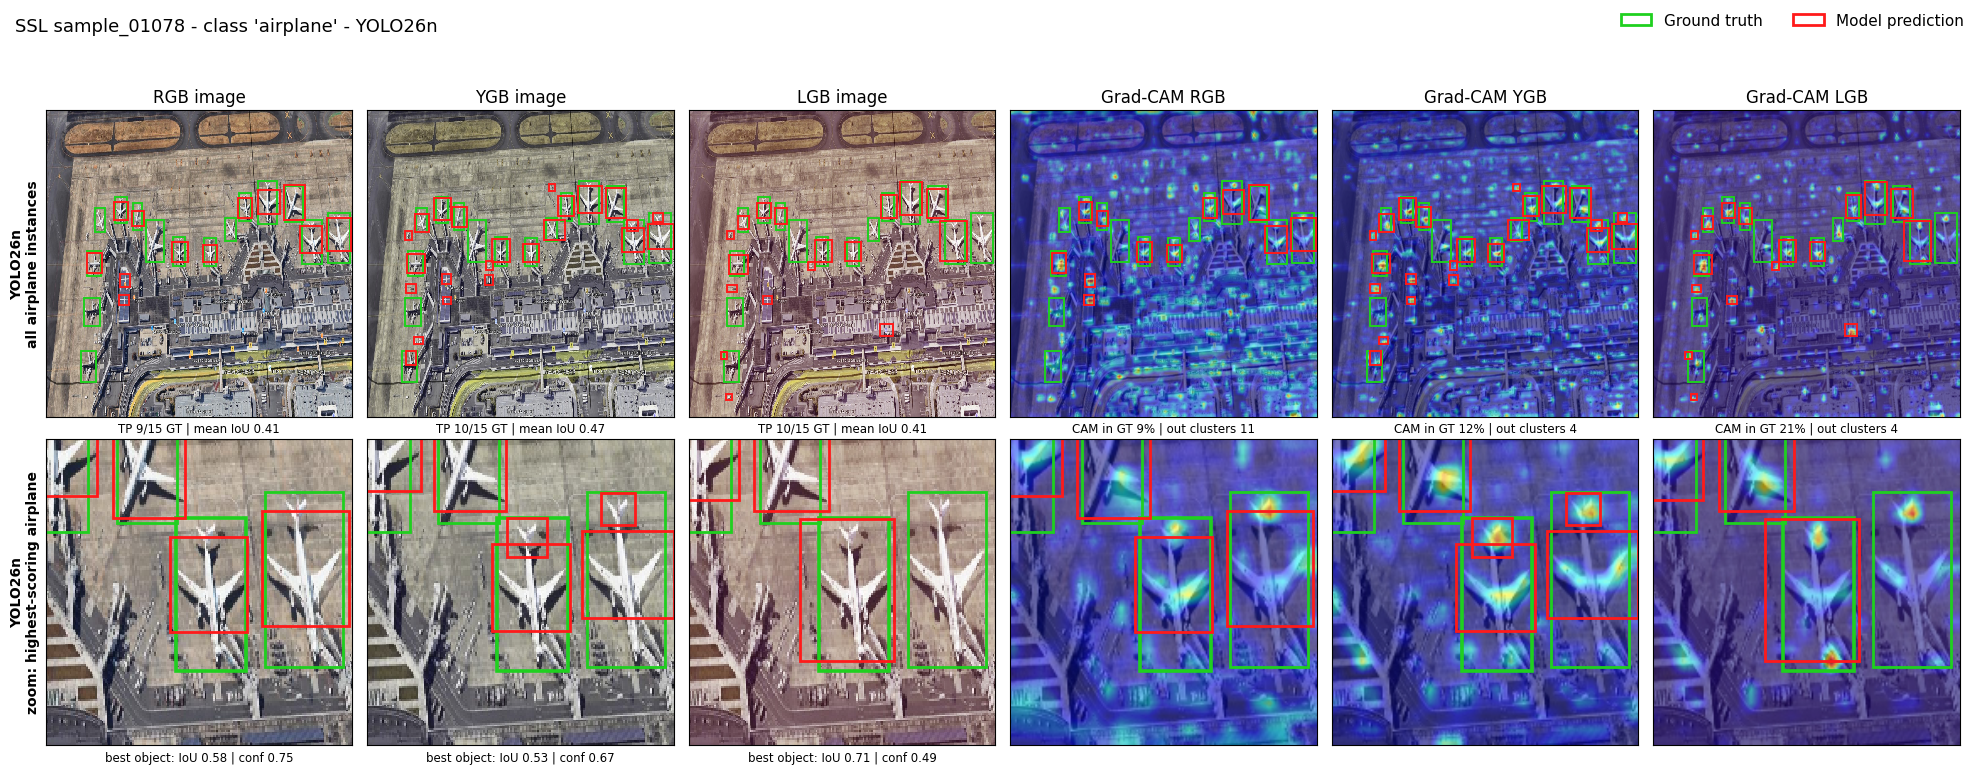

saved: C:\Users\DELL\Desktop\c\GradCAM_SSL_class_figures\YOLO26n_sample_01078_airplane_2rows.png


In [21]:
fig, axes = plt.subplots(2, 6, figsize=(6 * 3.3, 2 * 3.5 + 0.8))
draw_model_rows([axes[0], axes[1]], BUNDLE, MODEL_TAG)
fig.legend(handles=[Patch(fill=False, edgecolor=GREEN, label="Ground truth", linewidth=2),
                    Patch(fill=False, edgecolor=RED, label="Model prediction", linewidth=2)],
           loc="upper right", ncol=2, frameon=False, fontsize=11)
fig.suptitle(f"{DATASET_NAME} {IMAGE_STEM} - class '{CLASS_NAME}' - {MODEL_TAG}", x=0.01, ha="left", fontsize=13)
fig.tight_layout(rect=(0, 0, 1, 0.95))
out = OUTPUT_DIR / f"{MODEL_TAG}_{IMAGE_STEM}_{CLASS_NAME}_2rows.png"
fig.savefig(out, dpi=200, bbox_inches="tight"); plt.show(); print("saved:", out)

## 10. Metrics table

In [22]:
rows = [{"model": MODEL_TAG, "image": IMAGE_STEM, "class": CLASS_NAME, "representation": c, **METRICS[c]} for c in COLORS]
table = pd.DataFrame(rows)
table.to_csv(OUTPUT_DIR / f"{MODEL_TAG}_{IMAGE_STEM}_{CLASS_NAME}_metrics.csv", index=False)
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 40)
display(table.round(3))

,model,image,class,representation,n_GT,n_pred,TP,precision,recall,mean_IoU,focus_IoU,focus_conf,CAM_in_GT_pct,GT_area_share_pct,enrichment,outside_clusters,weighted_distance_px,GT_brightness,color_variance
0,YOLO26n,sample_01078,airplane,RGB,15,12,9,0.750,0.600,0.409,0.585,0.755,9.139000,8.028,1.138,11,153.153,152.67,1945.559
1,YOLO26n,sample_01078,airplane,YGB,15,23,10,0.435,0.667,0.473,0.530,0.670,12.382000,8.028,1.542,4,116.963,152.67,1945.559
2,YOLO26n,sample_01078,airplane,LGB,15,17,10,0.588,0.667,0.410,0.706,0.491,20.528999,8.028,2.557,4,121.093,152.67,1945.559


## 11. Notes

* Grad-CAM shows **where** the evidence for the class is in the chosen feature map; it does not say which colour channel mattered (that is what the channel ablation does). Its maximum is always 1 (per-image normalisation), so compare locations, not heat intensity, across models.
* With a whole-class target the heat-map lights up on all instances of the class — that is expected.
* **Next:** run this notebook for YOLO12n and YOLO26n with `USE_SAVED_SELECTION = True` (same image and class), then for Faster R-CNN save a bundle in the same format (see the combine notebook), then run `Combine_GradCAM_figure_all_models.ipynb`.